# 🟢 1. Basics: Computer Vision Foundations & The Convolution Operation

### *Why ANNs Fail on Images, Hubel & Wiesel Biological Insights, 2D Discrete Convolution, Kernels, Padding, and Stride*

---

## 📌 Module Overview
1. **Why Dense Neural Networks (ANN) Fail on Image Data**:
   - Destruction of spatial locality through 1D flattening.
   - Massive parameter explosion ($O(H 	imes W 	imes C)$).
   - Complete lack of translation invariance.
2. **Biological Inspiration (Hubel & Wiesel, 1959/1962)**: Simple cells (edge detection) and complex cells (translation tolerance).
3. **The 2D Convolution (Cross-Correlation) Operation**:
   - Mathematical formula, element-wise multiplication, and spatial accumulation.
   - Receptive fields and feature maps.
4. **Kernels as Feature Detectors**:
   - Sobel horizontal & vertical edge detectors, Ridge detection, Sharpening, and Gaussian Blur filters.
5. **Hyperparameters of Convolution**:
   - **Padding**: Valid ($P=0$) vs. Same ($P = \frac{K-1}{2}$).
   - **Stride ($S$)**: Downsampling rate and dimension formula:
     $$O = \left\lfloor \frac{W - K + 2P}{S} \right\rfloor + 1$$
6. **Pure NumPy Implementation from Scratch**:
   - Forward 2D Convolution applied to sample digit images showing extracted edge maps!


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import correlate2d
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'

SEED = 42
np.random.seed(SEED)
print("Vision Foundations environment ready.")


Vision Foundations environment ready.


## 1. Why Standard ANNs Fail on Images
Consider a standard high-resolution image: $224 \times 224 \times 3 = 150,528$ pixels.
1. **Parameter Explosion**: Connecting an input of $150,528$ pixels to a single hidden layer of $1,000$ neurons requires:
   $$150,528 \times 1,000 = 150,528,000 \text{ weights!}$$
   This leads to catastrophic overfitting, massive memory usage, and impossible training times.
2. **Loss of Spatial Topology**: In computer vision, a pixel at $(x, y)$ is intimately correlated with its neighbors at $(x \pm 1, y \pm 1)$. When an ANN flattens an image into a 1D vector, a pixel at row 1 is placed thousands of positions away from the pixel directly below it in row 2!
3. **No Translation Invariance**: If an object (e.g., a cat) moves 3 pixels to the right, a flattened ANN receives an entirely different input vector and must learn to recognize the cat from scratch in every pixel location.

**CNN Solution**:
* **Sparse Connectivity (Local Receptive Fields)**: Each neuron only connects to a tiny local patch (e.g., $3 \times 3$).
* **Parameter Sharing**: The *same* filter weights sweep across the entire image, detecting edges regardless of where they appear.


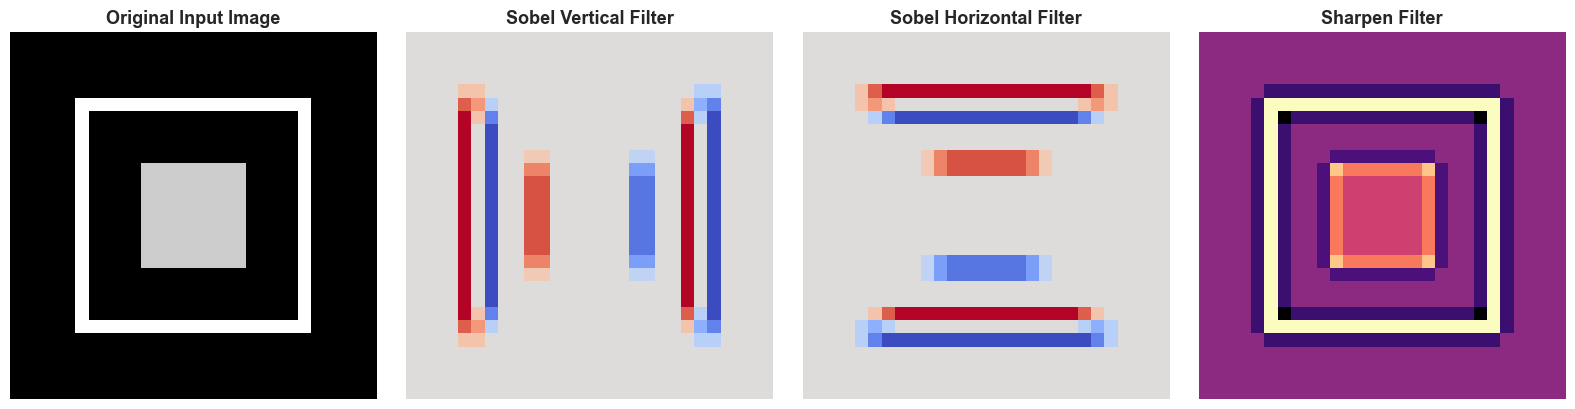

In [2]:
# 2. Applying Classical Kernels from Scratch to a Synthetic Shape
# Create a synthetic 28x28 geometric image with horizontal and vertical lines
canvas = np.zeros((28, 28))
canvas[5:23, 5] = 1.0    # Left vertical edge
canvas[5:23, 22] = 1.0   # Right vertical edge
canvas[5, 5:23] = 1.0    # Top horizontal edge
canvas[22, 5:23] = 1.0   # Bottom horizontal edge
canvas[10:18, 10:18] = 0.8 # Center square patch

# Define Classical Computer Vision Kernels
sobel_v = np.array([[-1, 0, 1],
                    [-2, 0, 2],
                    [-1, 0, 1]])

sobel_h = np.array([[-1, -2, -1],
                    [ 0,  0,  0],
                    [ 1,  2,  1]])

sharpen = np.array([[ 0, -1,  0],
                    [-1,  5, -1],
                    [ 0, -1,  0]])

# Apply convolution using 2D cross-correlation
feat_v = correlate2d(canvas, sobel_v, mode='same')
feat_h = correlate2d(canvas, sobel_h, mode='same')
feat_sharp = correlate2d(canvas, sharpen, mode='same')

# Visualizing Filter Responses
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(canvas, cmap='gray')
axes[0].set_title('Original Input Image')

axes[1].imshow(feat_v, cmap='coolwarm')
axes[1].set_title('Sobel Vertical Filter')

axes[2].imshow(feat_h, cmap='coolwarm')
axes[2].set_title('Sobel Horizontal Filter')

axes[3].imshow(feat_sharp, cmap='magma')
axes[3].set_title('Sharpen Filter')

for ax in axes:
    ax.axis('off')

plt.tight_layout()
plt.show()


## 3. Mathematical Mechanics: Padding & Stride
For an input of dimension $W \times H$, kernel size $K$, padding $P$, and stride $S$:

$$\text{Output Width } O_W = \left\lfloor \frac{W - K + 2P}{S} \right\rfloor + 1$$

* **Valid Padding ($P = 0$)**: No padding added. The filter cannot extend beyond boundaries. The spatial dimensions **shrink** with every layer ($O = W - K + 1$).
* **Same Padding ($P = \frac{K - 1}{2}$)**: Zeros are padded around the border so the output has the exact same spatial dimensions as the input when $S = 1$.
* **Stride ($S$)**: The step size the filter slides across the image. A stride of $S = 2$ halves the spatial resolution, functioning as a learned downsampling operation.


Input Shape:        (1, 28, 28)
Feature Maps Shape: (3, 28, 28) (3 learned filters)


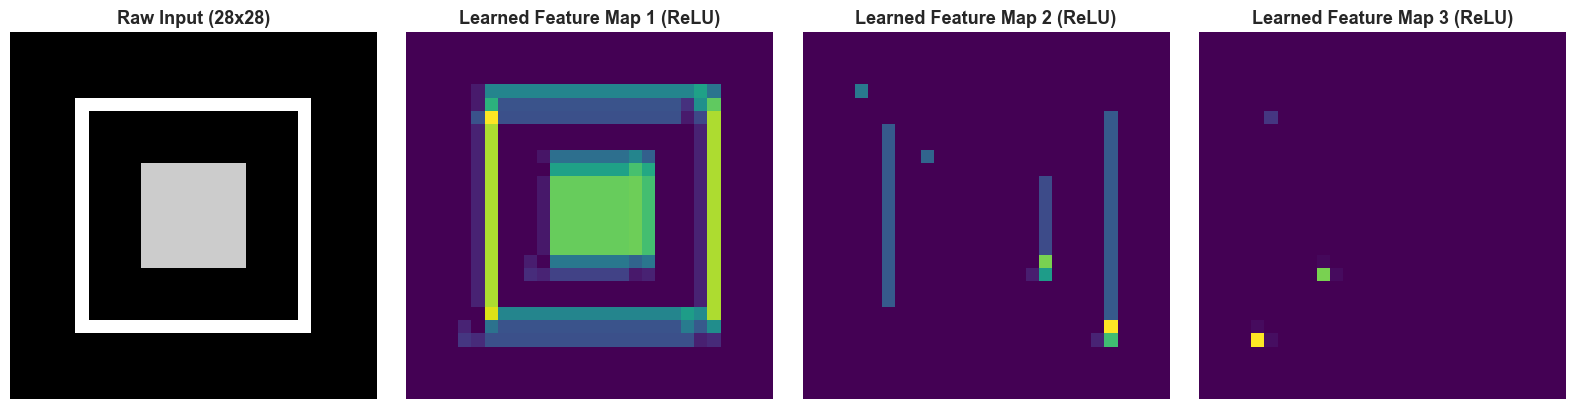

In [3]:
# 4. Pure NumPy 2D Convolution Layer from First Principles
class Conv2DFromScratch:
    """
    2D Convolutional Layer implemented from scratch in pure NumPy.
    """
    def __init__(self, in_channels, out_channels, kernel_size=3, stride=1, padding='same'):
        self.in_channels = in_channels
        self.out_channels = out_channels
        self.k = kernel_size
        self.stride = stride
        self.padding = padding
        # He Normal Weight Initialization
        limit = np.sqrt(2.0 / (in_channels * kernel_size * kernel_size))
        self.W = np.random.randn(out_channels, in_channels, kernel_size, kernel_size) * limit
        self.b = np.zeros((out_channels, 1))

    def _pad(self, X, pad_w):
        if pad_w == 0:
            return X
        return np.pad(X, ((0, 0), (pad_w, pad_w), (pad_w, pad_w)), mode='constant')

    def forward(self, X):
        # Input shape: (C_in, H, W)
        C_in, H, W = X.shape
        pad_w = (self.k - 1) // 2 if self.padding == 'same' else 0
        X_padded = self._pad(X, pad_w)
        H_pad, W_pad = X_padded.shape[1], X_padded.shape[2]

        H_out = int((H_pad - self.k) / self.stride) + 1
        W_out = int((W_pad - self.k) / self.stride) + 1
        out = np.zeros((self.out_channels, H_out, W_out))

        for f in range(self.out_channels):
            for i in range(H_out):
                for j in range(W_out):
                    h_start = i * self.stride
                    h_end = h_start + self.k
                    w_start = j * self.stride
                    w_end = w_start + self.k

                    slice_x = X_padded[:, h_start:h_end, w_start:w_end]
                    # Element-wise product across all channels and kernel dimensions
                    out[f, i, j] = np.sum(slice_x * self.W[f]) + self.b[f]

        # Apply ReLU activation
        return np.maximum(0, out)

# Demonstrate Conv2D forward pass on synthetic input
conv_layer = Conv2DFromScratch(in_channels=1, out_channels=3, kernel_size=3, stride=1, padding='same')
input_tensor = canvas.reshape(1, 28, 28)
feature_maps = conv_layer.forward(input_tensor)

print(f"Input Shape:        {input_tensor.shape}")
print(f"Feature Maps Shape: {feature_maps.shape} (3 learned filters)")

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(canvas, cmap='gray')
axes[0].set_title('Raw Input (28x28)')
axes[0].axis('off')

for f_idx in range(3):
    axes[f_idx + 1].imshow(feature_maps[f_idx], cmap='viridis')
    axes[f_idx + 1].set_title(f'Learned Feature Map {f_idx + 1} (ReLU)')
    axes[f_idx + 1].axis('off')

plt.tight_layout()
plt.show()


## 💡 Core Takeaways
1. **Weight Sharing & Local Receptive Fields** allow CNNs to process 2D/3D visual topologies with orders of magnitude fewer parameters than ANNs.
2. **Kernels act as pattern extractors**: Early layers learn edges and gradients; deeper layers compose them into textures, parts, and objects.
3. **Padding and Stride** control the output spatial resolution and receptive field expansion.
